# Data Preperation for Model Training and Evaluation

## 1) Gene Expression Dataset with Mice Epithelial Cells

In [ ]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
from anndata import AnnData
from sklearn.model_selection import train_test_split

In [ ]:
# File must first be downloaded at https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE92332
# ------------------------------------------------------------------
# Load RNA seq data
# ------------------------------------------------------------------
data_path = "data/epithelialrnaseq" # path to folder where data file is saved
df = pd.read_csv(os.path.join(data_path, "GSE92332_SalmHelm_UMIcounts.txt"), sep='\t') # path to data file
df = df.transpose()

In [ ]:
cell_groups = []
barcodes = []
conditions = []
cell_types = []

# extract information about the cell samples (eg. in scRNA-seq data, each row corresponds to a cell with a barcode, and each column corresponds to a gene with a gene id.)
for cell in df.index:
    cell_group, barcode, condition, cell_type = cell.split('_')
    cell_groups.append(cell_group)
    barcodes.append(barcode)
    conditions.append(condition)
    cell_types.append(cell_type)
    
conditions = np.array(conditions)

# preprocess the gene expression data
adata = AnnData(X = df.values, obs={
    "cell_groups": cell_groups,
    "barcodes": barcodes,
    "conditions": conditions,
    "cell_types": cell_types
})
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata) 
sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True) # select 2000 highly variable genes
 

In [ ]:
# Create datasets for model training and evaluation (control cells are selected as reference and infected cells as target)

def make_df(adata, condition, n, label):
    idx = (
        adata.obs.query("conditions == @condition")
        .sample(n=n, random_state=42)
        .index
    )

    df_out = pd.DataFrame(
        adata[idx].X.copy(),
        columns=df.columns[[int(i) for i in adata.var_names]].tolist()
    )
    df_out["label"] = label
    return df_out

# ------------------------------------------------------------------
# Select referece control cells and target infected cells
# ------------------------------------------------------------------
df_bk = make_df(adata, "Control", 1500, "Background")
df_s  = make_df(adata, "Salmonella", 1000, "Salmonella")
df_h  = make_df(adata, "Hpoly.Day10", 1000, "Hpoly.Day10")


bk_train, bk_test = train_test_split(df_bk, test_size=500, random_state=42)
sal_train, sal_test = train_test_split(df_s, test_size=500, random_state=42)
h_train, h_test = train_test_split(df_h, test_size=500, random_state=42)

# save train and test data
train_df = pd.concat([bk_train, sal_train, h_train], axis=0).sample(frac=1, random_state=42).to_csv(os.path.join(data_path,"train_EP_dataset.csv"),index=False)
test_df = pd.concat([bk_test, sal_test, h_test], axis=0).sample(frac=1, random_state=42).to_csv(os.path.join(data_path,"test_EP_dataset.csv"),index=False)

## 2) Toy Image Dataset (MNIST-based)

In [20]:
# Load MNIST data and create the toy unpaired reference-target dataset for training CASLVAE
import os
import numpy as np
import pandas as pd
import torch
import torchvision
import torchvision.transforms as T
from sklearn.model_selection import train_test_split

# ------------------------------------------------------------------
# Load MNIST
# ------------------------------------------------------------------
data_path = "data/images"

transform = T.ToTensor()

mnist = torchvision.datasets.MNIST(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

loader = torch.utils.data.DataLoader(
    mnist,
    batch_size=25000,
    shuffle=True
)

# Get two independent batches
(bg_images, bg_labels) = next(iter(loader))
(fg_images, fg_labels) = next(iter(loader))

# ------------------------------------------------------------------
# Select referece digits (0)
# ------------------------------------------------------------------
background = bg_images[bg_labels == 0].squeeze()

n_samples = 500

zero = background[:n_samples]
one = background[n_samples:2*n_samples] + fg_images[fg_labels == 1][:n_samples].squeeze()
two = background[2*n_samples:3*n_samples] + fg_images[fg_labels == 2][:n_samples].squeeze()
three = background[3*n_samples:4*n_samples] + fg_images[fg_labels == 3][:n_samples].squeeze()

zero_idx = np.where(bg_labels.numpy() == 0)[0][:n_samples]
one_idx = np.where(fg_labels.numpy() == 1)[0][:n_samples]
two_idx = np.where(fg_labels.numpy() == 2)[0][:n_samples]
three_idx = np.where(fg_labels.numpy() == 3)[0][:n_samples]

# ------------------------------------------------------------------
# Helper function
# ------------------------------------------------------------------
pixel_cols = [f"pixel{i}" for i in range(28 * 28)]

def make_df(images, label, digit_idx):
    df = pd.DataFrame(
        images.reshape(len(images), -1).numpy(),
        columns=pixel_cols
    )
    df["label"] = label
    df["digit_idx"] = digit_idx
    return df

# ------------------------------------------------------------------
# Create dataframes
# ------------------------------------------------------------------
df_0 = make_df(zero, "Background", zero_idx)
df_1 = make_df(one, 1, one_idx)
df_2 = make_df(two, 2, two_idx)
df_3 = make_df(three, 3, three_idx)

# ------------------------------------------------------------------
# Combine and save
# ------------------------------------------------------------------
train_df = (
    pd.concat([df_0, df_1, df_2, df_3], ignore_index=True)
      .sample(frac=1, random_state=42)
      .reset_index(drop=True)
)

train_df.to_csv(
    os.path.join(data_path, "train_toyimagedata.csv"),
    index=False
)

print(train_df.shape)
print(train_df["label"].value_counts())
print(f'Training data save to {os.path.join(data_path, "train_toyimagedata.csv")}')


(2000, 786)
3             500
Background    500
2             500
1             500
Name: label, dtype: int64
Training data save to data/images\train_toyimagedata.csv


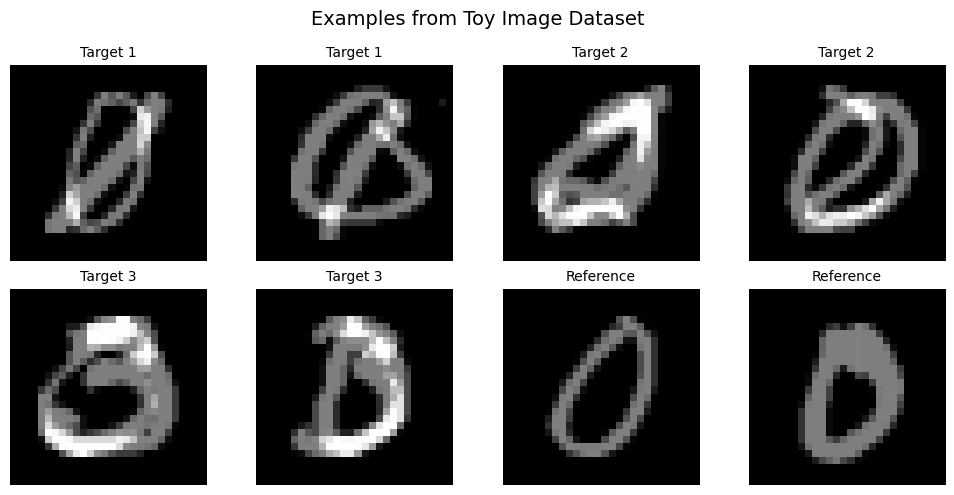

In [21]:
import matplotlib.pyplot as plt
import math

# Select 2 examples per class
indices = (
    train_df.index[train_df.label == 1][:2].tolist()
    + train_df.index[train_df.label == 2][:2].tolist()
    + train_df.index[train_df.label == 3][:2].tolist()
    + train_df.index[train_df.label == "Background"][:2].tolist()
)

# Global intensity limits
all_imgs = np.stack([train_df.iloc[i,:-2] for i in indices])
vmin = all_imgs.min().item()
vmax = all_imgs.max().item()

n_cols = 4
n_rows = math.ceil(len(indices) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(2.5 * n_cols, 2.5 * n_rows)
)

axes = axes.flatten()

for ax, idx in zip(axes, indices):

    ax.imshow(
        train_df.iloc[idx,:-2].astype(float).to_numpy().reshape(28, 28),
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    label = train_df.loc[idx, "label"]

    if label == "Background":
        title = "Reference"
    else:
        title = f"Target {label}"

    ax.set_title(title, fontsize=10)
    ax.axis("off")

# Hide unused axes
for ax in axes[len(indices):]:
    ax.axis("off")

fig.suptitle("Examples from Toy Image Dataset", fontsize=14)
plt.tight_layout()
plt.show()